<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_29_Hidden_State_Dimensionality_Reduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.gridspec import GridSpec

from PIL import Image
import requests
from io import BytesIO

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

# Part_1:Reducing Dimension while preserving shape

## Task_1:
- Use the online code to import the picture of the Stedelijk Museum
in Amsterdam and convert it to grayscale.
Calculate the SVD and visualize the three matrices and the
scree plot (scatter plot of sorted singular values) as shown in Figure
5.32

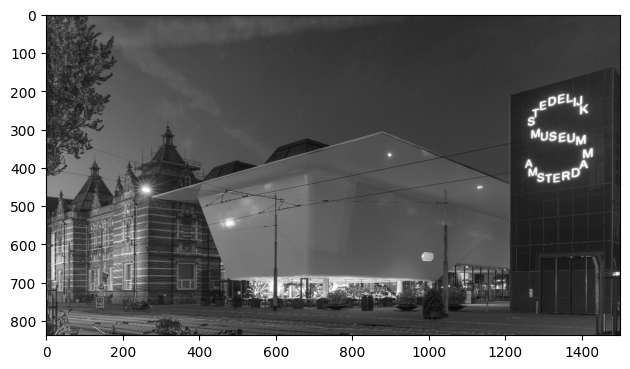

In [22]:

# url = 'https://upload.wikimedia.org/wikipedia/commons/6/61/De_nieuwe_vleugel_van_het_Stedelijk_Museum_Amsterdam.jpg'
url = 'https://sincxpress.com/De_nieuwe_vleugel_van_het_Stedelijk_Museum_Amsterdam.jpg'

response = requests.get(url,headers={'User-Agent':'Mozilla/5.0 (compatible; ImageLoader/1.0)'})
img = Image.open(BytesIO(response.content))

# convert to grayscale and numpy
img = np.array( img.convert('L') ,dtype=float)
img = img[::2,::2] # downsample

plt.imshow(img,cmap='gray')

plt.tight_layout()
plt.show()

In [23]:
# img1 = img[::2,::2]
# plt.imshow(img1,cmap='gray')
# plt.tight_layout()
# plt.show()

In [24]:
# img2 = img[::4,::4]
# plt.imshow(img2,cmap='gray')
# plt.tight_layout()
# plt.show()

In [25]:
# img3 = img[::6,::6]
# plt.imshow(img3,cmap='gray')
# plt.tight_layout()
# plt.show()

In [26]:
# img4 = img[::8,::8]
# plt.imshow(img4,cmap='gray')
# plt.tight_layout()
# plt.show()

In [27]:
# img5 = img[::10,::10]
# plt.imshow(img5,cmap='gray')
# plt.tight_layout()
# plt.show()

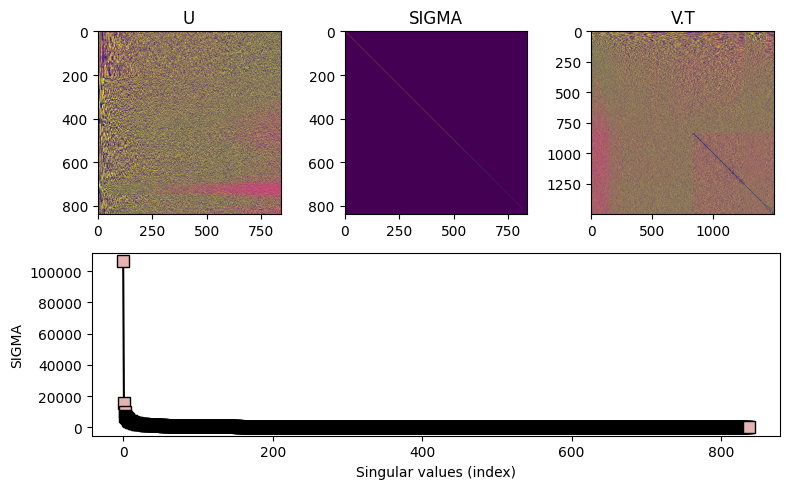

In [28]:


# SVD
U,s,Vh = np.linalg.svd(img)


# visualize
fig = plt.figure(figsize=(8,5))
gs = GridSpec(2,3,figure=fig)
ax1 = fig.add_subplot(gs[0,0])
ax2 = fig.add_subplot(gs[0,1])
ax3 = fig.add_subplot(gs[0,2])
ax4 = fig.add_subplot(gs[1,:])

ax1.imshow(U,vmin=-.01,vmax=.01,cmap='plasma')
ax1.set(title='U')

ax2.imshow(np.diag(s),vmin=0,vmax=200)
ax2.set(title='SIGMA')

ax3.imshow(Vh,vmin=-.01,vmax=.01,cmap='plasma')
ax3.set(title='V.T')

ax4.plot(s,'ks-',markerfacecolor=[.9,.7,.7],markersize=8)
ax4.set(xlabel='Singular values (index)',ylabel='SIGMA')

plt.tight_layout()
plt.show()


## Task_2:
- Transform the singular values to percent variance explained (as a
reminder: pcti = 100σ2
i/ σ2). Create a low-rank reconstruction
of the image by applying Equation 5.7 with r = 50. Calculate the
percent variance explained using those 50 components, and visualize
the original and reconstructed images as in Figure 5.33.